# Notebook 1 — The data: real bonds, 98 inputs, and what "filled" means

**What this notebook covers**

1. Where the data comes from (all free)
2. What one row of raw bond data looks like
3. Why bonds are hard: most do not trade every day
4. The inputs ("features") the models see
5. The golden rule: never peek into the future
6. The thing we predict: was a quote *filled*?
7. The finished table of 16,000 quote requests
8. How hard is this prediction problem?
9. Honest limitations of the data

New to bonds? Keep [GLOSSARY.md](../GLOSSARY.md) open in another tab.
Everything shown here is produced by `scripts/01_download_data.py` and `scripts/02_build_dataset.py`.

In [1]:
# Set-up: make the project's code importable and keep the output tidy.
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
%matplotlib inline

## 1. Where the data comes from

HSBC used 1.7 million of their own private quote requests on European corporate bonds.
Nobody outside the bank can see those. We use the closest thing that is public and free:

| What | Source | What it gives us |
|---|---|---|
| **Every US corporate bond trade**, summarised per bond per day | [Open Source Bond Asset Pricing](https://openbondassetpricing.com/data/) (built from FINRA's TRACE system) | prices, yields, spreads, duration, trading volume, the average price customers bought and sold at |
| Interest rates, credit spreads, VIX, inflation, unemployment ... | [FRED](https://fred.stlouisfed.org) (Federal Reserve Bank of St. Louis) | the state of the wider market each day |
| Stock-market factor returns | Kenneth French's data library | used to measure how each bond reacts to the stock market |
| Excess bond premium | Federal Reserve Board | a measure of credit-market stress |

Two differences from HSBC that we cannot avoid: our bonds are **American**, not European, and we see **trades**, not quote requests (section 6 explains how we bridge that gap).

We use exactly HSBC's dates: **24 July 2024 to 29 October 2024**.

## 2. What one row of raw data looks like

The raw file has one row per bond per day on which the bond traded. Let us load it and look at one heavily traded bond.

In [2]:
from qon.panel import load_panel
from qon.dataset import load_events, FEATURE_COLUMNS
panel = load_panel()
events = load_events()
main, calib, meta = events["main"], events["calibration"], events["meta"]

Panel: 7,663,200 rows read, 956 trading days (2021-01-04 .. 2024-10-29), 25,421 bonds; 6 thin holiday sessions dropped: ['2021-10-11', '2021-11-11', '2022-10-10', '2022-11-11', '2023-10-09', '2024-10-14']


In [3]:
# Pick the bond that appears most often in our test window and show its last few trading days.
bond = main["bond"].value_counts().index[0]
i = int(np.where(panel.bonds == bond)[0][0])
w = panel.wide
last = np.where(panel.traded[:, i])[0][-6:]
pd.DataFrame({
    "date": panel.dates[last],
    "price (% of face value)": w["pr"][last, i],
    "yield (%)": 100 * w["ytm"][last, i],
    "credit spread (%)": 100 * w["spread"][last, i],
    "duration (years)": w["mod_dur"][last, i],
    "trades that day": w["ntrades"][last, i],
    "customers bought at": w["ask"][last, i],
    "customers sold at": w["bid"][last, i],
}).round(3)

,date,price (% of face value),yield (%),credit spread (%),duration (years),trades that day,customers bought at,customers sold at
0,2024-10-22,98.8190,4.4730,0.2710,1.0170,11.0000,99.1660,98.7270
1,2024-10-23,99.0030,4.2950,0.0660,1.0150,5.0000,99.0160,NaN
2,2024-10-24,98.9640,4.3420,0.1290,1.0060,25.0000,99.0640,98.8290
3,2024-10-25,98.9010,4.4070,0.1810,1.0030,14.0000,98.9240,98.8200
4,2024-10-28,98.9530,4.3580,0.1060,1.0010,17.0000,98.9550,98.6260
5,2024-10-29,98.9770,4.3370,0.1000,0.9980,12.0000,99.0210,98.8370


**How to read this table**

* **price**: 98.5 means the bond costs \$985 for every \$1,000 that will be repaid at the end.
* **yield**: the yearly return an investor would earn by buying today and holding to the end.
* **credit spread**: how much more this bond yields than a US government bond of the same length. It is the market's price for the risk that the company does not pay.
* **duration**: how sensitive the price is to interest rates. Duration 7 means the price drops about 7% if yields rise by one percentage point.
* **customers bought at / sold at**: the average price investors paid when buying from dealers, and received when selling to dealers, that day. Buying costs more than selling brings; the gap is the dealers' fee (the *bid-ask spread*). These two columns are the key to our "fill" label.

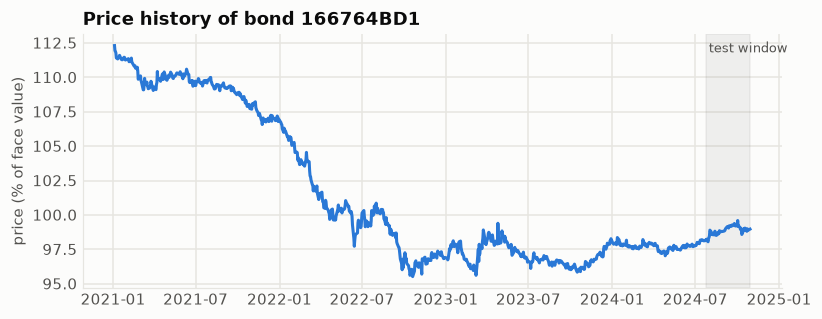

In [4]:
# The same bond's price over the whole history we loaded.
import matplotlib.pyplot as plt
from qon.analysis import _style, BLUE, INK2
plt = _style()
fig, ax = plt.subplots(figsize=(8.2, 3))
days = np.where(panel.traded[:, i])[0]
ax.plot(panel.dates[days], w["pr"][days, i], color=BLUE, lw=2)
ax.set_ylabel("price (% of face value)")
ax.set_title(f"Price history of bond {bond}")
ax.axvspan(np.datetime64(meta["window"][0]), np.datetime64(meta["window"][1]), color=INK2, alpha=0.08)
ax.annotate("test window", (np.datetime64(meta["window"][0]), ax.get_ylim()[1]), xytext=(2, -12),
            textcoords="offset points", fontsize=8.5, color=INK2)
plt.show()

The big fall in 2022 is not about this company: interest rates rose sharply that year, and when rates rise, the prices of existing bonds fall. This matters later: **most of a bond's day-to-day price movement comes from the whole market moving**, not from anything specific to the bond.

## 3. Why bonds are hard: most do not trade every day

A share of a big company trades thousands of times a minute. A typical corporate bond may not trade for days.

In [5]:
w0, w1 = panel.row_of(meta["window"][0]), panel.row_of(meta["window"][1])
in_window = panel.traded[w0:w1 + 1]
active = in_window.any(axis=0)
share_of_days = in_window[:, active].mean(axis=0)
print(f"Bonds that traded at least once in the test window: {active.sum():,}")
print(f"A typical (median) bond traded on {np.median(share_of_days):.0%} of the days.")
print(f"One bond in four traded on fewer than {np.quantile(share_of_days, 0.25):.0%} of the days.")
print(f"Bonds trading on any single day: about {int(np.median(in_window.sum(axis=1))):,}")

Bonds that traded at least once in the test window: 16,272
A typical (median) bond traded on 63% of the days.
One bond in four traded on fewer than 16% of the days.
Bonds trading on any single day: about 9,222


This is why a dealer cannot simply look up "the price" of a bond: the last trade may be days old. And it is why we restrict the study to bonds that are *liquid enough* for every input to be computed from real numbers:

* the bond traded within the last 5 trading days,
* it has three years of monthly price history,
* it has at least 15 day-to-day returns and at least 5 days with both customer buys and customer sells in the last three months.

About half of the bonds trading on a given day pass (roughly 5,000 bonds). HSBC's own universe is also the more liquid part of the market.

## 4. The inputs ("features") the models see

The team's list ([docs/Features_Qiskit.csv](../docs/Features_Qiskit.csv)) has 216 features. A feature is one number that describes the situation *before* a quote request arrives. We built **every feature that can be built from free data: 97 of the 216**, plus one extra input, the *side* of the request (does the customer want to buy or sell?).

In [6]:
from qon.feature_catalog import coverage_table
cov = coverage_table()
summary = cov.groupby("Category", sort=False)["status"].agg(
    in_the_list="size", built=lambda s: (s == "BUILT").sum())
summary.loc["TOTAL"] = summary.sum()
summary

,in_the_list,built
Category,,
Bond contract / static,18,7
"Yield, spread & valuation",22,11
Interest-rate risk,12,7
Credit rating,14,0
Bond momentum & reversal,18,17
Bond risk & return distribution,18,17
Bond factor betas,14,10
Liquidity & microstructure,22,12
Issuer fundamentals,24,0


**What each group means, in plain English**

| Group | The question it answers | Built? |
|---|---|---|
| Bond contract | What kind of loan is this? (interest rate, years left, size, industry) | partly: the rest needs a paid database of bond terms |
| Yield, spread & valuation | How is the market pricing it, and is it cheap or expensive versus similar bonds? | half: the rest needs ratings or derivative prices |
| Interest-rate risk | How much does it move when rates move? | most |
| Credit rating | What grade do the rating agencies give? | **none**: ratings are licensed |
| Momentum & reversal | Has the price been rising or falling? | almost all |
| Risk & return distribution | How bumpy has the ride been? | almost all |
| Factor betas | How does it react to the bond market, stock market, rates, oil, VIX? | most |
| Liquidity & microstructure | How easy is it to trade? | half: the rest needs individual trades |
| Issuer fundamentals | How healthy is the company's balance sheet? | **none**: needs paid accounting data linked to bonds |
| Equity-market signals | What is the company's share price doing? | **none**: needs a paid link from bonds to shares |
| Ownership, flows & supply | Who holds it, and is the company issuing more? | two |
| Macro & market-level | What is the wider market doing today? | most |

The full list, with how each feature was built or exactly why it could not be, is in [docs/FEATURE_COVERAGE.md](../docs/FEATURE_COVERAGE.md). A few examples:

In [7]:
examples = [2, 21, 41, 67, 85, 103, 117, 120, 125, 203]
cov[cov["number"].isin(examples)][["number", "Feature", "column", "how / why not"]].set_index("number")

,Feature,column,how / why not
number,,,
2,Time to maturity,f002_time_to_maturity,"Years to maturity at the last trade, rolled forward to the event day."
21,Credit spread (vs Treasury),f021_credit_spread,"Yield minus the Treasury yield of the same maturity, at the last trade."
41,Modified duration,f041_modified_duration,Modified duration at the last trade.
67,Short-term reversal (1m),f067_reversal_1m,Bond total return over the last month (21 trading days).
85,Total volatility (12m),f085_total_volatility_12m,Standard deviation of the last 12 monthly returns.
103,Bond market beta,f103_bond_market_beta,"Slope of 36 monthly excess returns on the corporate-bond market (value-weighted, built from the panel)."
117,Amihud illiquidity,f117_amihud_illiquidity,Average of |daily return| / $ millions traded over the last 63 trading days.
120,Effective spread (TRACE),f120_effective_spread,"Average of (customer buy price - customer sell price) / mid on days with both, last 63 days."
125,Zero-trading days %,f125_zero_trading_days,Share of the last 21 trading days with no trade.


In [8]:
# All 98 inputs of ONE quote request (the first event of the test window).
one = main.iloc[0]
print(f"Bond {one['bond']} on {one['date'].date()}, customer wants to {'BUY' if one['side'] == 1 else 'SELL'}")
one[FEATURE_COLUMNS].astype(float).round(4).to_frame("value").T.iloc[:, :12]

Bond 87165BAM5 on 2024-07-24, customer wants to SELL


,f000_rfq_side,f001_coupon_rate,f002_time_to_maturity,f003_bond_age,f004_age_over_original_maturity,f005_log_amount_outstanding,f016_rule_144a_flag,f018_industry_sector,f019_yield_to_maturity,f021_credit_spread,f024_spread_change_1m,f025_spread_change_3m
value,-1.0000,3.9500,3.3543,6.6530,0.6648,13.8155,0.0000,16.0000,0.0577,0.0148,-0.0007,-0.0004


## 5. The golden rule: never peek into the future

A quote request arrives on day *t*. Every input must be something a dealer could have known **before** that: we only use data up to the close of day *t − 1*.

This sounds obvious, but it is the most common way backtests fool people. If even one input accidentally contains a little of tomorrow's price, the model looks brilliant and is worthless in real life.

We do not just promise this; we test it. `tests/test_no_lookahead.py` computes all inputs for a day, then **destroys every piece of data from that day onwards** and computes them again. If a single number changes, the test fails. It passes for three different days.

One place where we are stricter than the HSBC paper: they scaled their features using the average and spread of the *whole* sample, which includes the future. We compute those only from data before the test window.

## 6. The thing we predict: was the quote *filled*?

### How bond trading works

An investor who wants to buy a bond sends a **request for quote (RFQ)** to several dealers at once. Each dealer replies with a price, without seeing the others' prices. The investor takes the best one. That dealer's quote is **filled**; the others are not. A dealer would love to know **p(fill)**, the probability that a quote will be filled, before sending it.

### The problem

Nobody publishes quote requests. Only *completed trades* are public.

### Our stand-in: replayed quotes

Every completed customer trade was the winning answer to a real request. So we replay history and add one simulated dealer:

1. Each (bond, day, direction) where customers really traded is one request.
2. Our dealer builds a **reference price**: the bond's last traded price, updated for how far the whole bond market has moved since then (long-duration bonds are moved more, because they react more).
3. Our dealer adds its **mark-up**: `kappa` × the bond's usual half bid-ask spread.
   * customer wants to buy → we *offer* at reference × (1 + mark-up)
   * customer wants to sell → we *bid* at reference × (1 − mark-up)
4. Our quote is **filled** if it would have beaten the price the customer really got that day.

So the bonds, prices and market conditions are real. Only the dealer's rule is ours.

**Why step 2 updates for the market move.** In section 2 we saw that bond prices mostly move together. Without the update, "was our quote filled?" would mostly mean "did the whole market go up or down today?", which nobody can predict and which every real dealer sees on their screen anyway. We checked this on calibration data: without the update, fills on the buy side and sell side were almost perfect mirror images of each other from day to day (correlation −0.9).

Here are two real examples from the test window:

In [9]:
kappa = meta["kappa"]
def explain(e):
    t = panel.row_of(e["date"]); j = int(np.where(panel.bonds == e["bond"])[0][0])
    markup = kappa * e["half_spread"]
    if e["side"] == 1:
        ours, real, word = e["ref_price"] * (1 + markup), float(panel.wide["ask"][t, j]), "paid"
        verdict = "FILLED (we were cheaper)" if ours <= real else "not filled (we were dearer)"
    else:
        ours, real, word = e["ref_price"] * (1 - markup), float(panel.wide["bid"][t, j]), "received"
        verdict = "FILLED (we paid more)" if ours >= real else "not filled (we paid less)"
    return {"date": e["date"].date(), "bond": e["bond"],
            "customer wants to": "buy" if e["side"] == 1 else "sell",
            "last traded price": round(e["f031_price"], 3),
            "reference (updated for market)": round(e["ref_price"], 3),
            "mark-up (%)": round(100 * markup, 3),
            "OUR quote": round(ours, 3), f"price customer really got": round(real, 3),
            "result": verdict, "label": int(e["filled"])}
picks = pd.concat([main[(main.side == 1) & (main.filled == 1)].iloc[[0]],
                   main[(main.side == 1) & (main.filled == 0)].iloc[[0]],
                   main[(main.side == -1) & (main.filled == 1)].iloc[[0]],
                   main[(main.side == -1) & (main.filled == 0)].iloc[[0]]])
pd.DataFrame([explain(e) for _, e in picks.iterrows()]).T

,0,1,2,3
date,2024-07-24,2024-07-24,2024-07-24,2024-07-24
bond,960386AM2,87264ABS3,55262CAE0,87165BAM5
customer wants to,buy,buy,sell,sell
last traded price,98.8390,90.6160,100.8000,94.5300
reference (updated for market),98.6970,90.4680,100.7480,94.4160
mark-up (%),0.1020,0.0900,0.4400,0.1640
OUR quote,98.7980,90.5490,100.3050,94.2610
price customer really got,98.8070,90.5230,99.3500,94.5120
result,FILLED (we were cheaper),not filled (we were dearer),FILLED (we paid more),not filled (we paid less)
label,1,0,1,0


### Setting the dealer's aggressiveness

`kappa` is the only free number in the rule. HSBC report that about 37% of their quotes were filled, so we chose kappa to give a 37% fill rate **on the calibration period**, then froze it.

In [10]:
print(f"kappa = {kappa:.3f}  (our dealer quotes {kappa:.2f} usual half-spreads away from its reference price)")
print(f"fill rate in the calibration period: {meta['fill_rate_calibration']:.1%}  (target 37%)")
print(f"fill rate in the test window:        {meta['fill_rate_main']:.1%}  (HSBC report about 37%)")

kappa = 1.380  (our dealer quotes 1.38 usual half-spreads away from its reference price)
fill rate in the calibration period: 37.2%  (target 37%)
fill rate in the test window:        37.4%  (HSBC report about 37%)


## 7. The finished table

In [11]:
print(f"Test window: {meta['window'][0]} to {meta['window'][1]}  ({meta['n_window_days']} trading days)")
print(f"Events: {len(main):,} in the test window, {len(calib):,} in the calibration period")
print(f"Events per day: {main.groupby('date').size().min()} to {main.groupby('date').size().max()}")
print(f"Different bonds: {main['bond'].nunique():,}")
print(f"Inputs per event: {len(FEATURE_COLUMNS)}")
print(f"Customer buys: {(main.side == 1).mean():.0%} of events; fill rate {main[main.side == 1].filled.mean():.1%}")
print(f"Customer sells: {(main.side == -1).mean():.0%} of events; fill rate {main[main.side == -1].filled.mean():.1%}")
print(f"Missing values: {int(main[FEATURE_COLUMNS].isna().sum().sum())}")

Test window: 2024-07-24 to 2024-10-29  (68 trading days)
Events: 16,000 in the test window, 8,000 in the calibration period
Events per day: 235 to 236
Different bonds: 4,944
Inputs per event: 98
Customer buys: 51% of events; fill rate 37.0%
Customer sells: 49% of events; fill rate 37.8%
Missing values: 0


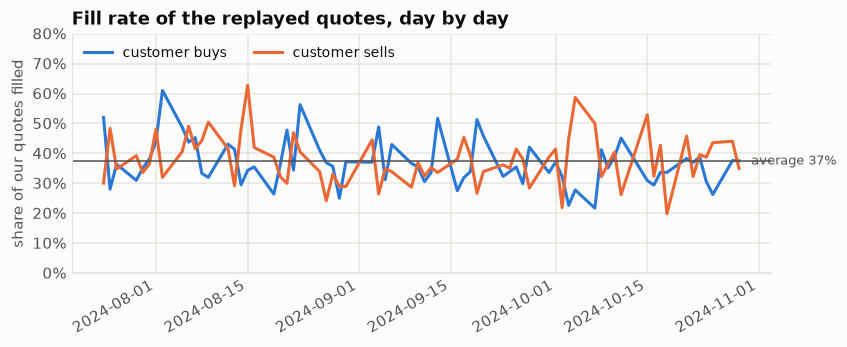

In [12]:
from qon.analysis import fig_fill_rate
from qon.feature_sets import combine_events
fig_fill_rate(combine_events(events));

The fill rate moves around from day to day (some days are simply easier for our dealer than others), but it stays in a sensible range and the two sides no longer mirror each other.

The test window has 68 trading days where HSBC count 69: 14 October 2024 (Columbus Day) is a US bond-market holiday on which only a few hundred trades are reported, so we leave it out.

## 8. How hard is this prediction problem?

Before any quantum computer is involved, how well can an ordinary model predict fills from these inputs? We answer using **only the calibration period**: train on its first 30 days, test on its last 10.

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from qon.stats import daily_auc
X, y, d = calib[FEATURE_COLUMNS].to_numpy(), calib["filled"].to_numpy(), calib["day_index"].to_numpy()
tr, te = d < 30, d >= 30
models = {"logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=3000)),
          "gradient boosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, max_depth=3, random_state=0)}
for name, m in models.items():
    p = m.fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    print(f"{name:20s} mean daily AUC on the held-out calibration days: {daily_auc(y[te], p, d[te]).mean():.3f}")
print("(0.5 = guessing, 1.0 = perfect)")

logistic regression  mean daily AUC on the held-out calibration days: 0.549
gradient boosting    mean daily AUC on the held-out calibration days: 0.555
(0.5 = guessing, 1.0 = perfect)


**AUC is about 0.55: a real but weak signal.** That is not a flaw; it is what honest fill prediction from market data looks like. HSBC's own classical models scored about 0.63 on their private data, which also includes information we do not have (the bank's own past quotes and fills).

What it means for our experiment: a tiny improvement would be hard to see, but an improvement of the size HSBC reported (AUC rising to 0.75–0.97) would be impossible to miss.

We also used the calibration period to pick the size of the training window. HSBC trained on the latest 500–2,000 events; our models needed 4,000 to pick up the signal, so 4,000 is the main setting and 1,000 is run as a check.

## 9. Honest limitations of the data

1. **The fill label is a stand-in.** Real quote requests are private. Our label says whether a simple simulated dealer would have beaten the real trade price. A real dealer quotes more cleverly, and real fills also depend on things we cannot see.
2. **We only see requests that ended in a trade.** When a customer asks for quotes and then walks away, nothing is published.
3. **Daily, not to the microsecond.** The public file gives one average price per bond, day and direction. HSBC's data is time-stamped to the microsecond.
4. **US bonds, not European.**
5. **97 of 216 features.** No credit ratings, no company accounts, no share prices, no CDS, no holdings data. All of those cost money.
6. **Liquid bonds only**, so that every input is a real number rather than a filled-in gap.

None of these stops us testing the *method*. They do mean our numbers are about this dataset, not about HSBC's.

**Next:** [Notebook 2](02_quantum_circuit_and_feature_sets.ipynb) explains the quantum circuit and the competing sets of inputs.